<a href="https://colab.research.google.com/github/619carey/ai-ml-coursework-projects/blob/main/week_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 Assignment: Evaluating and Preparing Your ML Model for Use

## 1. Test Evaluation & Train vs. Test Comparison (Overfitting / Underfitting)
* **Evaluation Metrics:** For churn classification, we track **Accuracy**, **Precision**, **Recall** (catching customers likely to leave), **F1-Score**, and **ROC-AUC**.
* **Overfitting / Underfitting Check:** Comparing training scores against test scores reveals generalization gaps. If training accuracy/ROC-AUC is substantially higher than test performance (e.g., greater than 5–10 percentage points apart with lower test recall), the model is **overfitting** training noise; if both scores are low across train and test sets, the model is **underfitting** (high bias).

## 2. Feature Importance & Domain Interpretation
* Using **permutation importance** (measuring how much model performance drops when a feature's values are randomly shuffled on the test set) shows which variables drive predictions.
* **Domain Alignment:** In telecom churn, features such as **contract type** (month-to-month vs. long-term), **tenure** (newer subscribers leave more often), and **monthly/total charges** strongly influence churn risk. Higher churn probability for short-tenure, month-to-month customers aligns with real-world subscription behavior.

## 3. Practical Use, Post-Deployment Care & Risks
* **Practical Deployment:** Export the fitted preprocessing and model artifact (`joblib`) into a batch scoring job or API/web app so customer retention teams can flag high-risk accounts and offer targeted discounts or support.
* **Post-Deployment Maintenance:** Monitor **data drift** (changes in customer billing/plans), **prediction drift**, and periodic **model performance** against actual churn outcomes, retraining when metrics degrade.
* **Key Limitation / Risk:** **Class imbalance and false negatives/positives**—missing a true churner loses recurring revenue, while misclassifying loyal customers wastes retention incentives. Additionally, serialized models require matching package versions and safe handling of untrusted files.

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
=== Train Metrics ===
Accuracy : 0.7959
Precision: 0.6452
Recall   : 0.5157
F1-Score : 0.5732
ROC-AUC  : 0.8378

=== Test Metrics ===
Accuracy : 0.7939
Precision: 0.6409
Recall   : 0.5107
F1-Score : 0.5685
ROC-AUC  : 0.8319

=== Test Classification Report ===
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.78      0.79      0.79      1407

=== Top Features by Permutation Importance (ROC-AUC Drop) ===


,Feature,Importance_Mean,Importance_Std
0,tenure,0.194341,0.016371
5,Contract_Two year,0.054054,0.008320
1,MonthlyCharges,0.036866,0.006117
4,Contract_One year,0.019333,0.004741
2,TotalCharges,0.015276,0.004362
7,PaymentMethod_Electronic check,0.008170,0.003267
9,PaperlessBilling_Yes,0.006762,0.002329
3,SeniorCitizen,0.003109,0.001202


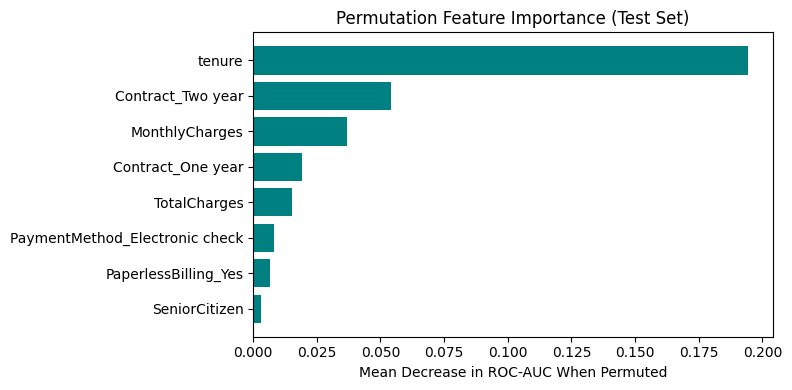

Saved artifact to telco_churn_model_bundle.joblib

=== New Customer Prediction (Loaded Model) ===
Predicted Churn Class : 1 (Yes)
Churn Probability     : 50.71%


In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load dataset
try:
    df.head()
except NameError:
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

# 2. Clean and prepare features
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"]).copy()

features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Contract",
    "PaymentMethod",
    "PaperlessBilling",
    "SeniorCitizen",
]
y = df["Churn"].map({"Yes": 1, "No": 0})
X = pd.get_dummies(df[features], drop_first=True)

# Fit scaler strictly on training split to prevent data leakage
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()
X_train[num_cols] = scaler.fit_transform(X_train_raw[num_cols])
X_test[num_cols] = scaler.transform(X_test_raw[num_cols])

# 3. Train model and compare Train vs. Test performance
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train, y_train)

for split_name, X_split, y_split in [
    ("Train", X_train, y_train),
    ("Test", X_test, y_test),
]:
    preds = model.predict(X_split)
    probs = model.predict_proba(X_split)[:, 1]
    print(f"=== {split_name} Metrics ===")
    print(f"Accuracy : {accuracy_score(y_split, preds):.4f}")
    print(f"Precision: {precision_score(y_split, preds):.4f}")
    print(f"Recall   : {recall_score(y_split, preds):.4f}")
    print(f"F1-Score : {f1_score(y_split, preds):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_split, probs):.4f}\n")

print("=== Test Classification Report ===")
print(classification_report(y_test, model.predict(X_test)))

# 4. Permutation Feature
perm = permutation_importance(
    model, X_test, y_test, n_repeats=15, random_state=42, scoring="roc_auc"
)
imp_df = pd.DataFrame(
    {
        "Feature": X_test.columns,
        "Importance_Mean": perm.importances_mean,
        "Importance_Std": perm.importances_std,
    }
).sort_values("Importance_Mean", ascending=False)

print("=== Top Features by Permutation Importance (ROC-AUC Drop) ===")
display(imp_df.head(8))

plt.figure(figsize=(8, 4))
top_imp = imp_df.head(8).iloc[::-1]
plt.barh(top_imp["Feature"], top_imp["Importance_Mean"], color="teal")
plt.xlabel("Mean Decrease in ROC-AUC When Permuted")
plt.title("Permutation Feature Importance (Test Set)")
plt.tight_layout()
plt.show()

# 5. Save model + scaler artifact and reload for new-data prediction
artifact_path = "telco_churn_model_bundle.joblib"
joblib.dump({"model": model, "scaler": scaler, "columns": list(X_train.columns)}, artifact_path)
print(f"Saved artifact to {artifact_path}")

loaded_bundle = joblib.load(artifact_path)
loaded_model = loaded_bundle["model"]
loaded_scaler = loaded_bundle["scaler"]
train_cols = loaded_bundle["columns"]

# a single new customer record matching raw feature schema
new_customer_raw = pd.DataFrame(
    [
        {
            "tenure": 3,
            "MonthlyCharges": 89.50,
            "TotalCharges": 268.50,
            "Contract": "Month-to-month",
            "PaymentMethod": "Electronic check",
            "PaperlessBilling": "Yes",
            "SeniorCitizen": 0,
        }
    ]
)

new_customer_enc = pd.get_dummies(new_customer_raw, drop_first=True).reindex(
    columns=train_cols, fill_value=0
)
new_customer_enc[num_cols] = loaded_scaler.transform(new_customer_enc[num_cols])

pred_class = loaded_model.predict(new_customer_enc)[0]
pred_prob = loaded_model.predict_proba(new_customer_enc)[0, 1]

print("\n=== New Customer Prediction (Loaded Model) ===")
print(f"Predicted Churn Class : {pred_class} ({'Yes' if pred_class == 1 else 'No'})")
print(f"Churn Probability     : {pred_prob:.2%}")